In [1]:
import utilities

utilities.download_istat()

already downloaded: data/raw/istat/metadata_41_983.xml
already downloaded: data/raw/istat/accidents_2015_2017.csv
already downloaded: data/raw/istat/accidents_2018_2020.csv
already downloaded: data/raw/istat/accidents_2021_2023.csv
already downloaded: data/raw/istat/accidents_2024_2026.csv
all chunks combined: (233538, 16)


In [2]:
utilities.download_situas()

already downloaded: data/raw/situas/situas_comuni_2020.csv




### 2.First look at the datas 



In [3]:
# libraries

from bs4 import BeautifulSoup
import pandas as pd

In [4]:
# ISTAT – road accidents

istat = pd.read_csv("data/raw/istat_accidents_all.csv")
print(istat.shape)
istat.head(20)

(233538, 16)


,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,1001,KILLINJ,F,2015,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,1001,KILLINJ,F,2016,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,1001,KILLINJ,F,2017,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,1001,KILLINJ,F,2018,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,1001,KILLINJ,M,2015,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,IT1:41_983(1.0),A,1001,KILLINJ,M,2016,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,IT1:41_983(1.0),A,1001,KILLINJ,M,2017,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,IT1:41_983(1.0),A,1001,KILLINJ,M,2018,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,IT1:41_983(1.0),A,1001,ROADACC,9,2015,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,IT1:41_983(1.0),A,1001,ROADACC,9,2016,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
istat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233538 entries, 0 to 233537
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   DATAFLOW          233538 non-null  object 
 1   FREQ              233538 non-null  object 
 2   REF_AREA          233538 non-null  int64  
 3   DATA_TYPE         233538 non-null  object 
 4   RESULT            233538 non-null  object 
 5   TIME_PERIOD       233538 non-null  int64  
 6   OBS_VALUE         233538 non-null  int64  
 7   OBS_STATUS        0 non-null       float64
 8   NOTE_DS           0 non-null       float64
 9   NOTE_REF_AREA     0 non-null       float64
 10  NOTE_DATA_TYPE    0 non-null       float64
 11  NOTE_RESULT       0 non-null       float64
 12  NOTE_TIME_PERIOD  0 non-null       float64
 13  BASE_PER          0 non-null       float64
 14  UNIT_MEAS         0 non-null       float64
 15  UNIT_MULT         0 non-null       float64
dtypes: float64(9), int64

In [6]:
istat.describe()

,REF_AREA,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
count,233538.000000,233538.000000,233538.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,45121.574853,2019.393405,16.914292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,32530.119459,2.831495,180.715035,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1001.000000,2015.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,16160.000000,2017.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,40011.000000,2019.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,72041.000000,2022.000000,7.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,111107.000000,2024.000000,17306.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# missing values in each column
istat.isna().sum() 

DATAFLOW                 0
FREQ                     0
REF_AREA                 0
DATA_TYPE                0
RESULT                   0
TIME_PERIOD              0
OBS_VALUE                0
OBS_STATUS          233538
NOTE_DS             233538
NOTE_REF_AREA       233538
NOTE_DATA_TYPE      233538
NOTE_RESULT         233538
NOTE_TIME_PERIOD    233538
BASE_PER            233538
UNIT_MEAS           233538
UNIT_MULT           233538
dtype: int64

In [8]:
###Comments

#   233,538 rows and 16 columns, but 9 columns (`OBS_STATUS`, `NOTE_*`, `BASE_PER`, `UNIT_*`) are **completely empty** → we will drop them.
#  `DATAFLOW` and `FREQ` have only one value (dataset id and "A" = annual) → not useful.
#  `REF_AREA` (the municipality code) was read as a **number**: `001001` became `1001`, so we lost the leading zeros. We need to read it as text, otherwise we cannot join it with other data.
#  `OBS_VALUE` is the number we are interested in, but we don't know yet *what* it counts: this depends on `DATA_TYPE` and `RESULT`.


In [9]:
# let's look at the categorical columns
for col in ["DATAFLOW", "FREQ", "DATA_TYPE", "RESULT", "TIME_PERIOD"]:
    print(istat[col].value_counts())
    print("-----")

DATAFLOW
IT1:41_983(1.0)    233538
Name: count, dtype: int64
-----
FREQ
A    233538
Name: count, dtype: int64
-----
DATA_TYPE
KILLINJ    155692
ROADACC     77846
Name: count, dtype: int64
-----
RESULT
F    77846
M    77846
9    77846
Name: count, dtype: int64
-----
TIME_PERIOD
2015    24141
2016    24000
2017    23934
2018    23862
2019    23745
2020    23712
2021    23712
2022    23712
2023    23703
2024    19017
Name: count, dtype: int64
-----


In [10]:
# which combinations of DATA_TYPE and RESULT exist?
istat.groupby(["DATA_TYPE", "RESULT"]).size()

DATA_TYPE  RESULT
KILLINJ    F         77846
           M         77846
ROADACC    9         77846
dtype: int64

In [11]:
# meaning of the codes, read from the ISTAT metadata (see utilities.read_codelist)
print(utilities.read_codelist("CL_TIPO_DATO22", ["ROADACC", "KILLINJ"]))
print(utilities.read_codelist("CL_ESITO", ["M", "F", "9"]))

{'KILLINJ': 'killed and injured', 'ROADACC': 'road accidents with injuries'}
{'M': 'killed', 'F': 'injured', '9': 'total'}


### 2.2 SITUAS – population and area

In [12]:
situas = pd.read_csv("data/raw/situas/situas_comuni_2020.csv", sep=";")
print(situas.shape)
situas.head(20)

(7903, 17)


,Codice Ripartizione geografica,Codice Regione,Codice Provincia (Storico),Codice Provincia/Uts,Codice Comune (alfanumerico),Codice Comune (numerico),Comune,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente)
0,1,1,1,201,1001,1001,Agliè,NaN,TO,0,0,2644,2011,"13,1462",2020,2545,2020
1,1,1,1,201,1002,1002,Airasca,NaN,TO,0,0,3819,2011,"15,7393",2020,3633,2020
2,1,1,1,201,1003,1003,Ala di Stura,NaN,TO,0,0,462,2011,"46,3315",2020,459,2020
3,1,1,1,201,1004,1004,Albiano d'Ivrea,NaN,TO,0,0,1791,2011,"11,7314",2020,1638,2020
4,1,1,1,201,1006,1006,Almese,NaN,TO,0,0,6303,2011,"17,8756",2020,6355,2020
5,1,1,1,201,1007,1007,Alpette,NaN,TO,0,0,277,2011,"5,6261",2020,235,2020
6,1,1,1,201,1008,1008,Alpignano,NaN,TO,0,0,16893,2011,"11,9193",2020,16484,2020
7,1,1,1,201,1009,1009,Andezeno,NaN,TO,0,0,1966,2011,"7,4860",2020,2013,2020
8,1,1,1,201,1010,1010,Andrate,NaN,TO,0,0,512,2011,"9,3085",2020,488,2020
9,1,1,1,201,1011,1011,Angrogna,NaN,TO,0,0,870,2011,"38,8782",2020,838,2020


In [13]:
situas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7903 entries, 0 to 7902
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Codice Ripartizione geografica  7903 non-null   int64 
 1   Codice Regione                  7903 non-null   int64 
 2   Codice Provincia (Storico)      7903 non-null   int64 
 3   Codice Provincia/Uts            7903 non-null   int64 
 4   Codice Comune (alfanumerico)    7903 non-null   int64 
 5   Codice Comune (numerico)        7903 non-null   int64 
 6   Comune                          7902 non-null   object
 7   Comune (dizione straniera)      124 non-null    object
 8   Sigla automobilistica           7811 non-null   object
 9   Capoluogo di Provincia/Uts      7903 non-null   int64 
 10  Capoluogo di Regione            7903 non-null   int64 
 11  Popolazione legale              7903 non-null   int64 
 12  Anno Censimento                 7903 non-null   

In [14]:
situas.isna().sum()

Codice Ripartizione geografica       0
Codice Regione                       0
Codice Provincia (Storico)           0
Codice Provincia/Uts                 0
Codice Comune (alfanumerico)         0
Codice Comune (numerico)             0
Comune                               1
Comune (dizione straniera)        7779
Sigla automobilistica               92
Capoluogo di Provincia/Uts           0
Capoluogo di Regione                 0
Popolazione legale                   0
Anno Censimento                      0
Superficie (Kmq)                     0
Anno (Superficie)                    0
Popolazione residente                0
Anno (Popolazione residente)         0
dtype: int64

In [15]:
# "Comune (dizione straniera)" is almost empty: which municipalities have it?
foreign = situas[situas["Comune (dizione straniera)"].notna()]
print(len(foreign))
print(foreign["Sigla automobilistica"].value_counts())
foreign[["Comune", "Comune (dizione straniera)"]].head()

124
Sigla automobilistica
BZ    116
TS      4
GO      3
TN      1
Name: count, dtype: int64


,Comune,Comune (dizione straniera)
2648,Aldino/Aldein,Aldein
2649,Andriano/Andrian,Andrian
2650,Anterivo/Altrei,Altrei
2651,Appiano sulla strada del vino/Eppan an der Wei...,Eppan an der Weinstraße
2652,Avelengo/Hafling,Hafling


- `Comune (dizione straniera)` is empty for 7,779 municipalities: this is **expected**, the column is filled only for the 124 municipalities with an official name in another language (German in Bolzano, Slovene in Trieste/Gorizia). The bilingual name is already in `Comune`, so we will drop this column.

In [16]:
# Missing values in Comune(dizione straniera) and Sigla automobilistica

print(situas[situas["Comune"].isna()][["Codice Comune (alfanumerico)", "Comune", "Sigla automobilistica"]])
print(situas[situas["Sigla automobilistica"].isna()][["Comune", "Sigla automobilistica"]].head())

     Codice Comune (alfanumerico) Comune Sigla automobilistica
164                          1168    NaN                    TO
        Comune Sigla automobilistica
5066    Acerra                   NaN
5067  Afragola                   NaN
5068   Agerola                   NaN
5069  Anacapri                   NaN
5070    Arzano                   NaN


In [ ]:
# What we notice:

# - 7,903 rows = all the Italian municipalities existing on 31/12/2020.
# - `Superficie (Kmq) (area) was read as **text**, because decimals use a comma (`13,1462`) and Rome even has a thousands separator (`1.287,3716`).
# - `Codice Comune (alfanumerico)` lost its leading zeros, like `REF_AREA` in ISTAT.
# - The missing values are **not real missing values**: pandas reads the text `"NA"` as NaN, so the province code of **Napoli (NA)** disappears (92 municipalities), and the municipality called **"None"** (Piedmont) loses its name!
# - Population and area are from **2020** (`Anno (Popolazione residente)` = 2020 for all rows), while `Popolazione legale` comes from the **2011 census**. This is the "year specific" warning of the assignment: we will use the 2020 resident population.
# - Population goes from 29 people (Morterone) to 2.77 million (Rome): very different sizes, we will need to keep this in mind for the rates per inhabitant.


### 3. Data cleaning

In [18]:
# ISTAT - road accidents

# As ref_area is a code not a number we force pandas to read the csv as text with `dtype={"REF_AREA": str}`.*

istat = pd.read_csv("data/raw/istat_accidents_all.csv", dtype={"REF_AREA": str})
istat.head(20)

,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,001001,KILLINJ,F,2015,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,001001,KILLINJ,F,2016,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,001001,KILLINJ,F,2017,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,001001,KILLINJ,F,2018,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,001001,KILLINJ,M,2015,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,IT1:41_983(1.0),A,001001,KILLINJ,M,2016,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,IT1:41_983(1.0),A,001001,KILLINJ,M,2017,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,IT1:41_983(1.0),A,001001,KILLINJ,M,2018,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,IT1:41_983(1.0),A,001001,ROADACC,9,2015,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,IT1:41_983(1.0),A,001001,ROADACC,9,2016,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# copy only the columns we need for the analysis.

istat1 = istat[["REF_AREA", "DATA_TYPE", "RESULT", "TIME_PERIOD", "OBS_VALUE"]].copy()


In [20]:
# Dropping the empty columns
# create a new column, measure that tell us whta OBS_VALUE is counting(than to what found in the metadata)

istat = istat.drop(["DATAFLOW", "FREQ", "OBS_STATUS", "NOTE_DS", "NOTE_REF_AREA",
                    "NOTE_DATA_TYPE", "NOTE_RESULT", "NOTE_TIME_PERIOD",
                    "BASE_PER", "UNIT_MEAS", "UNIT_MULT"], axis=1)


# combine the two codes and rename it 
istat["measure"] = istat["DATA_TYPE"] + "_" + istat["RESULT"]
istat["measure"] = istat["measure"].replace({"ROADACC_9": "accidents",
                                             "KILLINJ_M": "killed",
                                             "KILLINJ_F": "injured"})
istat["measure"].value_counts()

measure
injured      77846
killed       77846
accidents    77846
Name: count, dtype: int64

In [21]:
# one small table for each measure
acc = istat[istat["measure"] == "accidents"][["REF_AREA", "TIME_PERIOD", "OBS_VALUE"]]
acc = acc.rename(columns={"OBS_VALUE": "accidents"})

inj = istat[istat["measure"] == "injured"][["REF_AREA", "TIME_PERIOD", "OBS_VALUE"]]
inj = inj.rename(columns={"OBS_VALUE": "injured"})

kil = istat[istat["measure"] == "killed"][["REF_AREA", "TIME_PERIOD", "OBS_VALUE"]]
kil = kil.rename(columns={"OBS_VALUE": "killed"})

# join them side by side on municipality code + year
accidents = acc.merge(inj, how="inner", on=["REF_AREA", "TIME_PERIOD"])
accidents = accidents.merge(kil, how="inner", on=["REF_AREA", "TIME_PERIOD"])

accidents = accidents.rename(columns={"REF_AREA": "code", "TIME_PERIOD": "year"})
print(accidents.shape)
accidents.head(10)

(77846, 5)


,code,year,accidents,injured,killed
0,001001,2015,5,9,0
1,001001,2016,5,8,0
2,001001,2017,0,0,0
3,001001,2018,1,1,0
4,001002,2015,11,18,0
5,001002,2016,7,13,0
6,001002,2017,10,16,0
7,001002,2018,9,13,0
8,001003,2015,0,0,0
9,001003,2016,1,1,0


In [22]:
# missing values in each column
accidents.isna().sum()

code         0
year         0
accidents    0
injured      0
killed       0
dtype: int64

### 2024 has fewer rows, let's inspect it 

In [23]:
print("municipalities per year:")
print(accidents.groupby("year").size())

print("municipalities with 0 accidents in 2023:", (accidents[accidents["year"] == 2023]["accidents"] == 0).sum())
print("municipalities with 0 accidents in 2024:", (accidents[accidents["year"] == 2024]["accidents"] == 0).sum())

# data in 2024 not complete/not published?? 
# 

municipalities per year:
year
2015    8047
2016    8000
2017    7978
2018    7954
2019    7915
2020    7904
2021    7904
2022    7904
2023    7901
2024    6339
dtype: int64
municipalities with 0 accidents in 2023: 1643
municipalities with 0 accidents in 2024: 0


In [24]:
#If we leave them out, every average for 2024 would be too high. So we add them back with 0 accidents, 0 killed and 0 injured.
#This way, the data for 2024 will be more representative.
#We take as reference the municipalities that exist in 2023 but are missing in 2024.

codes_2023 = accidents[accidents["year"] == 2023]["code"]
codes_2024 = accidents[accidents["year"] == 2024]["code"]

# municipalities that are in 2023 but not in 2024
missing_2024 = codes_2023[~codes_2023.isin(codes_2024)]
print("missing in 2024:", len(missing_2024))

zeros_2024 = pd.DataFrame({"code": missing_2024,
                           "year": 2024,
                           "accidents": 0,
                           "injured": 0,
                           "killed": 0})

accidents = pd.concat([accidents, zeros_2024], ignore_index=True)
accidents.groupby("year").size()

missing in 2024: 1566


year
2015    8047
2016    8000
2017    7978
2018    7954
2019    7915
2020    7904
2021    7904
2022    7904
2023    7901
2024    7905
dtype: int64

Before joining with SITUAS we save the **national totals per year**

In [25]:
national = accidents.groupby("year")[["accidents", "injured", "killed"]].sum()
national

,accidents,injured,killed
year,,,
2015,174539,246920,3428
2016,175791,249175,3283
2017,174933,246750,3378
2018,172553,242919,3334
2019,172183,241384,3173
2020,118298,159248,2395
2021,151875,204728,2875
2022,165889,223475,3159
2023,166525,224634,3039


### 3.2 SITUAS – population and area
We reload the file with the right parameters:

In [26]:
situas = pd.read_csv("data/raw/situas/situas_comuni_2020.csv",
                     sep=";", decimal=",", thousands=".",
                     keep_default_na=False,
                     dtype={"Codice Comune (alfanumerico)": str})
situas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7903 entries, 0 to 7902
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Codice Ripartizione geografica  7903 non-null   int64  
 1   Codice Regione                  7903 non-null   int64  
 2   Codice Provincia (Storico)      7903 non-null   int64  
 3   Codice Provincia/Uts            7903 non-null   int64  
 4   Codice Comune (alfanumerico)    7903 non-null   object 
 5   Codice Comune (numerico)        7903 non-null   int64  
 6   Comune                          7903 non-null   object 
 7   Comune (dizione straniera)      7903 non-null   object 
 8   Sigla automobilistica           7903 non-null   object 
 9   Capoluogo di Provincia/Uts      7903 non-null   int64  
 10  Capoluogo di Regione            7903 non-null   int64  
 11  Popolazione legale              7903 non-null   int64  
 12  Anno Censimento                 79

In [ ]:
# check: Rome area is now a number, the municipality "None" has its name back, Napoli is "NA"

print(situas[situas["Comune"] == "Roma"]["Superficie (Kmq)"])
print(situas[situas["Codice Comune (alfanumerico)"] == "001168"]["Comune"])
print((situas["Sigla automobilistica"] == "NA").sum())

4729    1287.3716
Name: Superficie (Kmq), dtype: float64
164    None
Name: Comune, dtype: object
92


We keep only the columns we need and give them English names. We also add the name of the macro area and of the region (the file only has their codes).

In [28]:
situas = situas[["Codice Comune (alfanumerico)", "Comune", "Sigla automobilistica",
                 "Codice Regione", "Codice Ripartizione geografica",
                 "Capoluogo di Provincia/Uts", "Popolazione residente", "Superficie (Kmq)"]]

situas = situas.rename(columns={"Codice Comune (alfanumerico)": "code",
                                "Comune": "municipality",
                                "Sigla automobilistica": "province",
                                "Codice Regione": "region_code",
                                "Codice Ripartizione geografica": "area_code",
                                "Capoluogo di Provincia/Uts": "is_province_capital",
                                "Popolazione residente": "population",
                                "Superficie (Kmq)": "area_km2"})

In [29]:
# names of macro areas and regions (the dictionaries are in utilities.py)
situas["macro_area"] = situas["area_code"].replace(utilities.macro_areas)
situas["region"] = situas["region_code"].replace(utilities.regions)

### 3.3 Joining the two datasets
We use a **left join**: we keep all the ISTAT rows and add population and area where the municipality code is found in SITUAS.

In [30]:
df = accidents.merge(situas, how="left", on="code")
print(df.shape)

# rows without a match in SITUAS
not_matched = df[df["municipality"].isna()]
not_matched.groupby("year").size()

(79412, 14)


year
2015    385
2016    311
2017    122
2018     79
2019     16
2020      1
2021      3
2022      3
2023      5
2024      9
dtype: int64

In [31]:
# how many accidents do we lose if we drop them?
check = df.groupby("year").agg(total_accidents=("accidents", "sum"))
check["not_matched"] = not_matched.groupby("year")["accidents"].sum()
check["not_matched_%"] = (check["not_matched"] / check["total_accidents"] * 100).round(2)
check

,total_accidents,not_matched,not_matched_%
year,,,
2015,174539,1745,1.00
2016,175791,1645,0.94
2017,174933,513,0.29
2018,172553,286,0.17
2019,172183,25,0.01
2020,118298,0,0.00
2021,151875,13,0.01
2022,165889,10,0.01
2023,166525,12,0.01


In [ ]:
df = df[df["municipality"].notna()].copy()

# after the left join some columns became float because of the missing values: back to int

for col in ["region_code", "area_code", "is_province_capital", "population"]:
    df[col] = df[col].astype(int)

print(df.shape)
df.info()

(78478, 14)
<class 'pandas.core.frame.DataFrame'>
Index: 78478 entries, 0 to 79411
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   code                 78478 non-null  object 
 1   year                 78478 non-null  int64  
 2   accidents            78478 non-null  int64  
 3   injured              78478 non-null  int64  
 4   killed               78478 non-null  int64  
 5   municipality         78478 non-null  object 
 6   province             78478 non-null  object 
 7   region_code          78478 non-null  int64  
 8   area_code            78478 non-null  int64  
 9   is_province_capital  78478 non-null  int64  
 10  population           78478 non-null  int64  
 11  area_km2             78478 non-null  float64
 12  macro_area           78478 non-null  object 
 13  region               78478 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 9.0+ MB


In [33]:
# save the clean data
import os
os.makedirs("data/processed", exist_ok=True)

df.to_csv("data/processed/accidents_clean.csv", index=False)
national.to_csv("data/processed/national_by_year.csv")

### 4.Explanatory data analysis

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme()

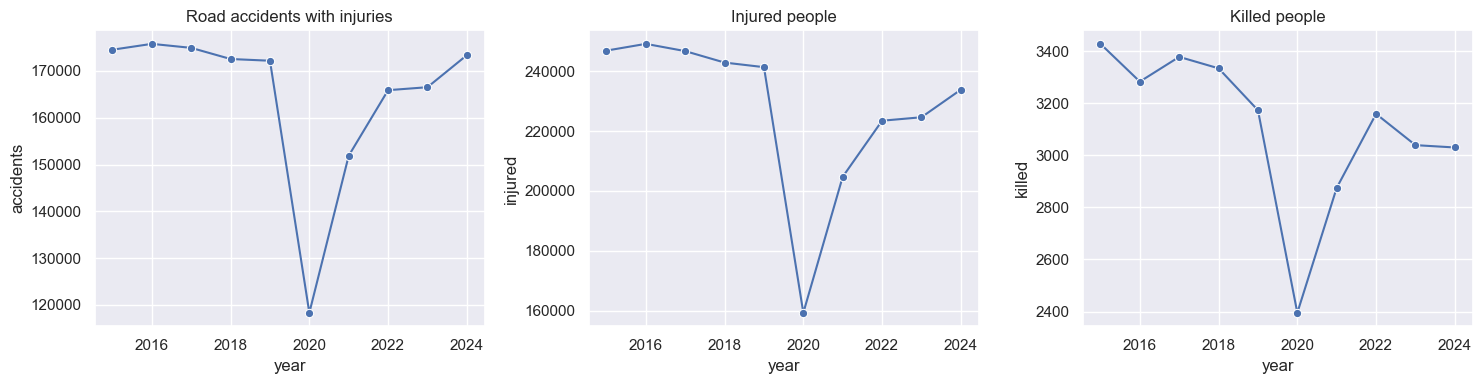

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.lineplot(data=national, x="year", y="accidents", marker="o", ax=axes[0])
axes[0].set_title("Road accidents with injuries")

sns.lineplot(data=national, x="year", y="injured", marker="o", ax=axes[1])
axes[1].set_title("Injured people")

sns.lineplot(data=national, x="year", y="killed", marker="o", ax=axes[2])
axes[2].set_title("Killed people")

plt.tight_layout()
plt.show()

In [36]:
# percentage change from one year to the next
national["accidents_change_%"] = (national["accidents"].pct_change() * 100).round(1)
national[["accidents", "accidents_change_%"]]

,accidents,accidents_change_%
year,,
2015,174539,NaN
2016,175791,0.7
2017,174933,-0.5
2018,172553,-1.4
2019,172183,-0.2
2020,118298,-31.3
2021,151875,28.4
2022,165889,9.2
2023,166525,0.4


### Distribution of accidents by municipality

In [37]:
latest = df[df["year"] >= 2022]

mun = latest.groupby(["code", "municipality", "province", "region", "macro_area", "population", "area_km2"],
                     as_index=False).agg(accidents=("accidents", "mean"),
                                         injured=("injured", "mean"),
                                         killed=("killed", "mean"),
                                         years=("year", "count"))

print(mun["years"].value_counts())

# keep only the municipalities with data for all 3 years
mun = mun[mun["years"] == 3]
print(mun.shape)
mun.head()

years
3    7896
1       5
Name: count, dtype: int64
(7896, 11)


,code,municipality,province,region,macro_area,population,area_km2,accidents,injured,killed,years
0,001001,Agliè,TO,Piemonte,North-West,2545,13.1462,2.666667,5.333333,0.333333,3
1,001002,Airasca,TO,Piemonte,North-West,3633,15.7393,5.333333,8.000000,0.333333,3
2,001003,Ala di Stura,TO,Piemonte,North-West,459,46.3315,0.666667,1.000000,0.000000,3
3,001004,Albiano d'Ivrea,TO,Piemonte,North-West,1638,11.7314,3.333333,5.666667,0.000000,3
4,001006,Almese,TO,Piemonte,North-West,6355,17.8756,4.000000,4.666667,0.333333,3


In [38]:
mun[["accidents", "injured", "killed", "population", "area_km2"]].describe().round(1)

,accidents,injured,killed,population,area_km2
count,7896.0,7896.0,7896.0,7896.0,7896.0
mean,21.3,28.8,0.4,7501.2,38.2
std,197.7,248.6,2.0,41885.3,50.9
min,0.0,0.0,0.0,29.0,0.1
25%,1.0,1.3,0.0,991.8,11.5
50%,3.3,5.0,0.0,2413.5,22.4
75%,11.3,16.3,0.3,6254.0,44.7
max,13307.3,16612.3,146.0,2770226.0,1287.4


In [39]:
print("skewness of accidents:", round(stats.skew(mun["accidents"]), 1))
print("municipalities with 0 accidents on average:", (mun["accidents"] == 0).sum())

skewness of accidents: 48.5
municipalities with 0 accidents on average: 719


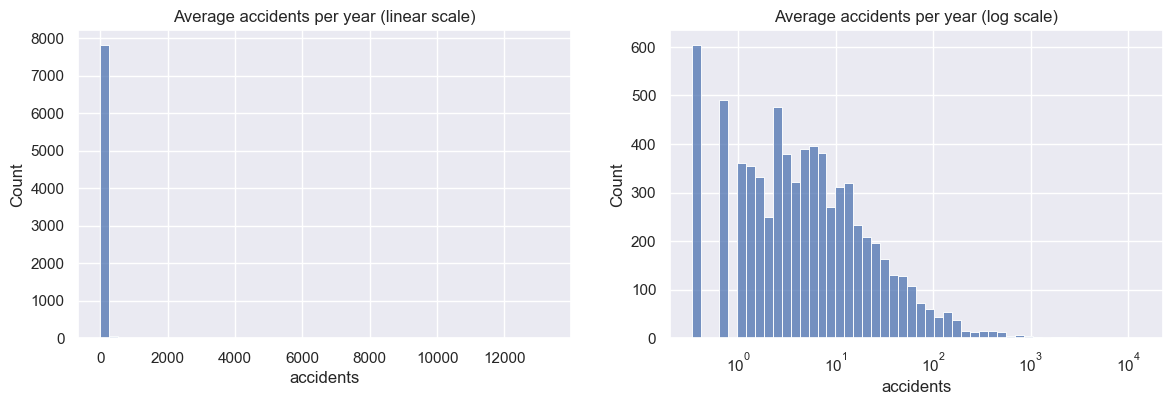

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=mun, x="accidents", bins=50, ax=axes[0])
axes[0].set_title("Average accidents per year (linear scale)")

# with a log scale we can see the shape of the distribution (municipalities with 0 accidents are not shown)
sns.histplot(data=mun, x="accidents", bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Average accidents per year (log scale)")

plt.show()

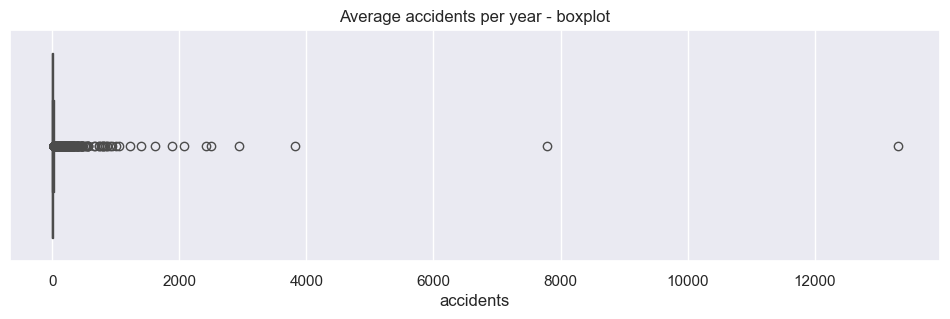

In [41]:
plt.figure(figsize=(12, 3))
sns.boxplot(data=mun, x="accidents")
plt.title("Average accidents per year - boxplot")
plt.show()

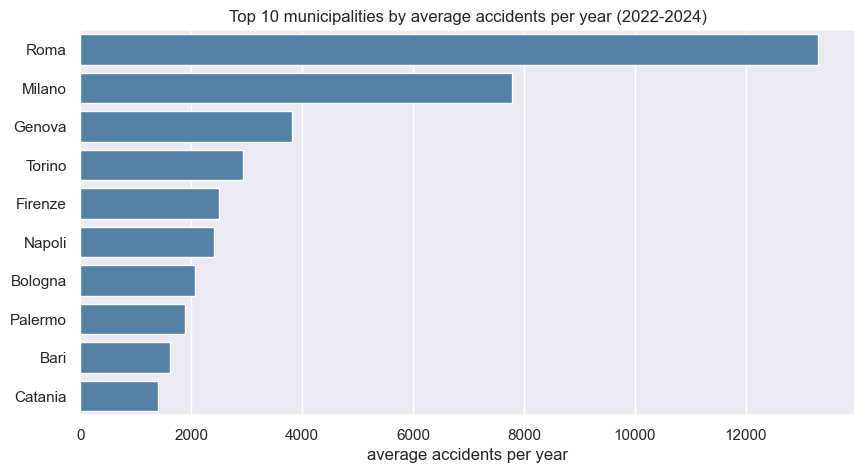

share of all Italian accidents in these 10 cities: 23.6 %


,municipality,province,accidents,killed,population
4727,Roma,RM,13307.333333,146.000000,2770226
1775,Milano,MI,7779.333333,43.000000,1374582
1266,Genova,GE,3817.000000,14.000000,566410
267,Torino,TO,2940.333333,23.333333,858205
4228,Firenze,FI,2499.333333,13.666667,368419
5112,Napoli,NA,2420.000000,31.666667,922094
3841,Bologna,BO,2074.666667,18.333333,391686
6602,Palermo,PA,1889.333333,22.666667,637885
5886,Bari,BA,1615.333333,11.666667,317205
6839,Catania,CT,1401.333333,15.000000,300356


In [ ]:
# Top 10 municipalities by number of accidents

top10 = mun.sort_values("accidents", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x="accidents", y="municipality", color="steelblue")
plt.title("Top 10 municipalities by average accidents per year (2022-2024)")
plt.xlabel("average accidents per year")
plt.ylabel("")
plt.show()

print("share of all Italian accidents in these 10 cities:",
      round(top10["accidents"].sum() / mun["accidents"].sum() * 100, 1), "%")
top10[["municipality", "province", "accidents", "killed", "population"]]

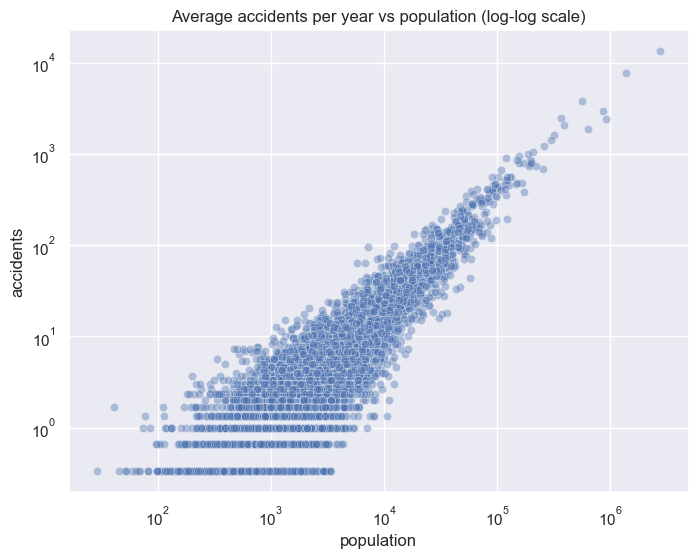

correlation: 0.976


In [ ]:
### Accidents vs population

plt.figure(figsize=(8, 6))
sns.scatterplot(data=mun[mun["accidents"] > 0], x="population", y="accidents", alpha=0.4)
plt.xscale("log")
plt.yscale("log")
plt.title("Average accidents per year vs population (log-log scale)")
plt.show()

print("correlation:", round(mun["accidents"].corr(mun["population"]), 3))

In [ ]:
### Geographical comparison

area = mun.groupby("macro_area", as_index=False).agg(accidents=("accidents", "sum"),
                                                     population=("population", "sum"),
                                                     municipalities=("code", "count"))

area["accidents_share_%"] = (area["accidents"] / area["accidents"].sum() * 100).round(1)
area["population_share_%"] = (area["population"] / area["population"].sum() * 100).round(1)
area

,macro_area,accidents,population,municipalities,accidents_share_%,population_share_%
0,Centre,42846.000000,11784536,968,25.4,19.9
1,Islands,14308.000000,6423749,767,8.5,10.8
2,North-East,35982.333333,11587355,1388,21.3,19.6
3,North-West,47658.000000,15895040,2990,28.3,26.8
4,South,27775.000000,13539074,1783,16.5,22.9


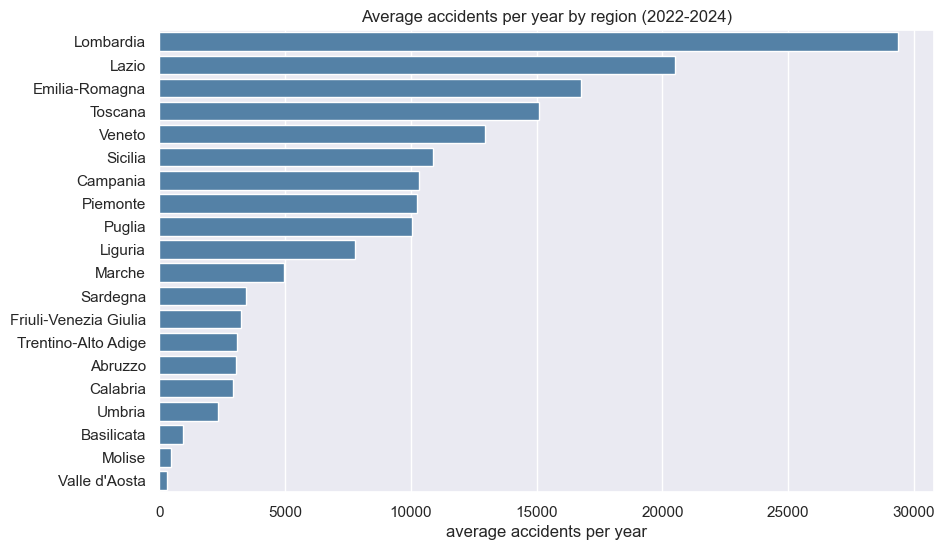

In [48]:
region = mun.groupby("region", as_index=False)["accidents"].sum()
region = region.sort_values("accidents", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=region, x="accidents", y="region", color="steelblue")
plt.title("Average accidents per year by region (2022-2024)")
plt.xlabel("average accidents per year")
plt.ylabel("")
plt.show()

In [ ]:
### Correlation

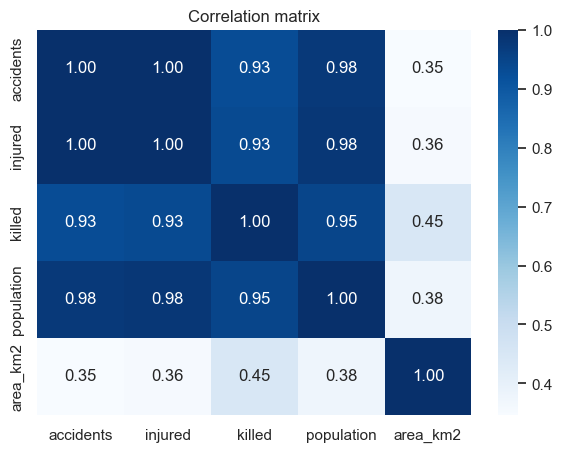

In [ ]:
### Correlation

corr = mun[["accidents", "injured", "killed", "population", "area_km2"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation matrix")
plt.show()

## 5. New columns: accident rates
In section 4 we saw that the absolute number of accidents mostly reflects the **size** of a municipality. To compare municipalities fairly we create new columns:
 
`accidents_per_1000`

`accidents_per_km2` 

`killed_per_100_acc` 

`density` 

In [51]:
mun["accidents_per_1000"] = mun["accidents"] / mun["population"] * 1000
mun["accidents_per_km2"] = mun["accidents"] / mun["area_km2"]

# if a municipality has 0 accidents the division gives NaN (0/0): we set it to 0
mun["killed_per_100_acc"] = (mun["killed"] / mun["accidents"] * 100).fillna(0)

mun["density"] = mun["population"] / mun["area_km2"]

mun[["accidents_per_1000", "accidents_per_km2", "killed_per_100_acc", "density"]].describe().round(2)

,accidents_per_1000,accidents_per_km2,killed_per_100_acc,density
count,7896.00,7896.00,7896.00,7896.00
mean,1.79,0.63,3.75,299.25
std,1.59,1.63,10.58,637.26
min,0.00,0.00,0.00,0.79
25%,0.78,0.04,0.00,42.91
50%,1.52,0.15,0.00,103.66
75%,2.42,0.52,3.25,277.82
max,40.65,42.82,200.00,11885.77


In [52]:
# national average, as a reference

national_rate = mun["accidents"].sum() / mun["population"].sum() * 1000
print("Italy: accidents per 1,000 inhabitants =", round(national_rate, 2))

Italy: accidents per 1,000 inhabitants = 2.85


In [53]:
mun.sort_values("accidents_per_1000", ascending=False).head(10)[["municipality", "province", "population", "accidents", "accidents_per_1000"]]

,municipality,province,population,accidents,accidents_per_1000
153,Moncenisio,TO,41,1.666667,40.650407
2712,Ponte Gardena/Waidbruck,BZ,201,3.666667,18.242123
486,Argentera,CN,78,1.333333,17.094017
1498,Brienno,CO,335,5.666667,16.915423
1318,Carrodano,SP,476,7.333333,15.406162
1041,Bard,AO,112,1.666667,14.880952
858,Belforte Monferrato,AL,502,7.333333,14.608234
318,Balocco,VC,220,3.000000,13.636364
645,Pietraporzio,CN,74,1.000000,13.513514
4174,Forte dei Marmi,LU,7217,94.333333,13.070990


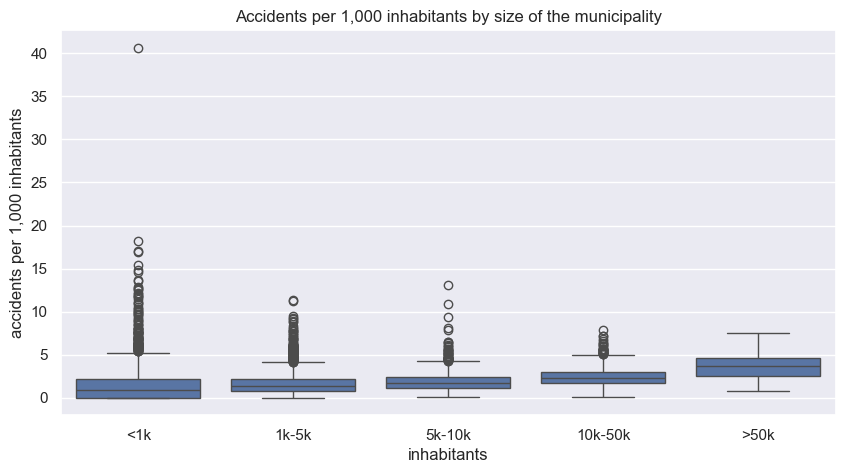

,count,median,std,max
size_class,,,,
<1k,1995,0.92,2.30,40.65
1k-5k,3530,1.33,1.23,11.31
5k-10k,1165,1.76,1.14,13.07
10k-50k,1064,2.26,1.09,7.85
>50k,142,3.67,1.37,7.53


In [54]:
# The ranking is full of small towns. With so few inhabitants, one accident more or less changes the rate completely
# Let's check how the rate behaves by size of the municipality:

# group the municipalities by size
mun["size_class"] = pd.cut(mun["population"],
                           bins=[0, 1000, 5000, 10000, 50000, 10000000],
                           labels=["<1k", "1k-5k", "5k-10k", "10k-50k", ">50k"])

plt.figure(figsize=(10, 5))
sns.boxplot(data=mun, x="size_class", y="accidents_per_1000")
plt.title("Accidents per 1,000 inhabitants by size of the municipality")
plt.xlabel("inhabitants")
plt.ylabel("accidents per 1,000 inhabitants")
plt.show()

mun.groupby("size_class", observed=True)["accidents_per_1000"].agg(["count", "median", "std", "max"]).round(2)


- Small municipalities have the **most extreme values** (max 40.7 for <1k inhabitants) and the most variable rates.

- At the same time, the **median** rate grows with size: 0.92 for municipalities under 1,000 inhabitants, 3.67 for cities over 50,000. Bigger cities have more traffic, so more accidents per inhabitant.

To build a reliable ranking we keep only municipalities with **at least 10,000 inhabitants**:

In [55]:
for threshold in [1000, 5000, 10000, 20000, 50000]:
    selected = mun[mun["population"] >= threshold]
    print(threshold, "inhabitants or more:",
          len(selected), "municipalities |",
          round(selected["accidents"].sum() / mun["accidents"].sum() * 100, 1), "% of accidents |",
          round(selected["population"].sum() / mun["population"].sum() * 100, 1), "% of population")

1000 inhabitants or more: 5903 municipalities | 99.0 % of accidents | 98.2 % of population
5000 inhabitants or more: 2371 municipalities | 90.6 % of accidents | 83.5 % of population
10000 inhabitants or more: 1206 municipalities | 81.2 % of accidents | 69.5 % of population
20000 inhabitants or more: 510 municipalities | 68.0 % of accidents | 53.3 % of population
50000 inhabitants or more: 142 municipalities | 49.9 % of accidents | 34.4 % of population


In [56]:
big = mun[mun["population"] >= 10000].copy()
print(big.shape)

(1206, 16)


### 5.2 Rankings

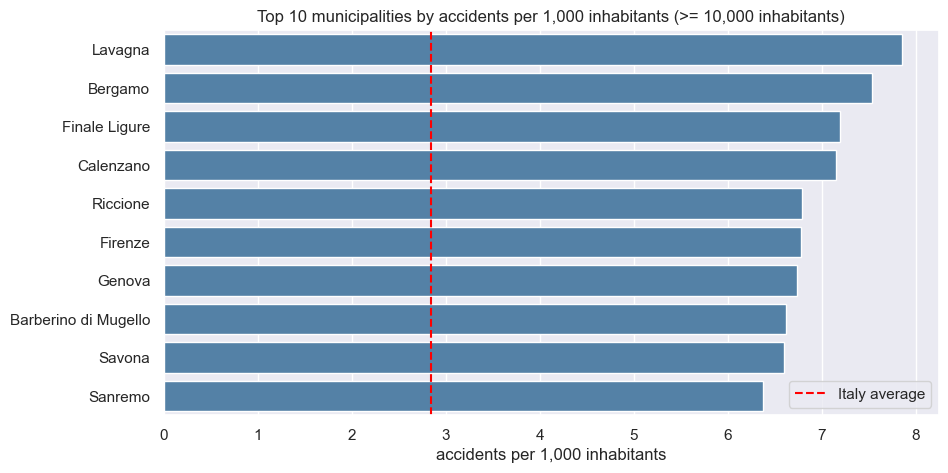

,municipality,province,population,accidents,accidents_per_1000
1269,Lavagna,GE,12352,97.00,7.85
1860,Bergamo,BG,119993,903.67,7.53
1201,Finale Ligure,SV,11304,81.33,7.20
4219,Calenzano,FI,18420,131.67,7.15
7515,Riccione,RN,34942,237.33,6.79
4228,Firenze,FI,368419,2499.33,6.78
1266,Genova,GE,566410,3817.00,6.74
4217,Barberino di Mugello,FI,10870,72.00,6.62
1228,Savona,SV,58949,389.33,6.60
1159,Sanremo,IM,53451,341.00,6.38


In [57]:
top_rate = big.sort_values("accidents_per_1000", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_rate, x="accidents_per_1000", y="municipality", color="steelblue")
plt.axvline(national_rate, color="red", linestyle="--", label="Italy average")
plt.title("Top 10 municipalities by accidents per 1,000 inhabitants (>= 10,000 inhabitants)")
plt.xlabel("accidents per 1,000 inhabitants")
plt.ylabel("")
plt.legend()
plt.show()

top_rate[["municipality", "province", "population", "accidents", "accidents_per_1000"]].round(2)

# Ranking contains bigger cities as Bergamo, Florence, Genoa, Savona...
# Many of them are tourist towns (Lavagna, Finale Ligure, Riccione, Sanremo): they have many more people on the roads than their resident population, so the rate per inhabitant is partly inflated. This is a limit of using resident population as the denominator.

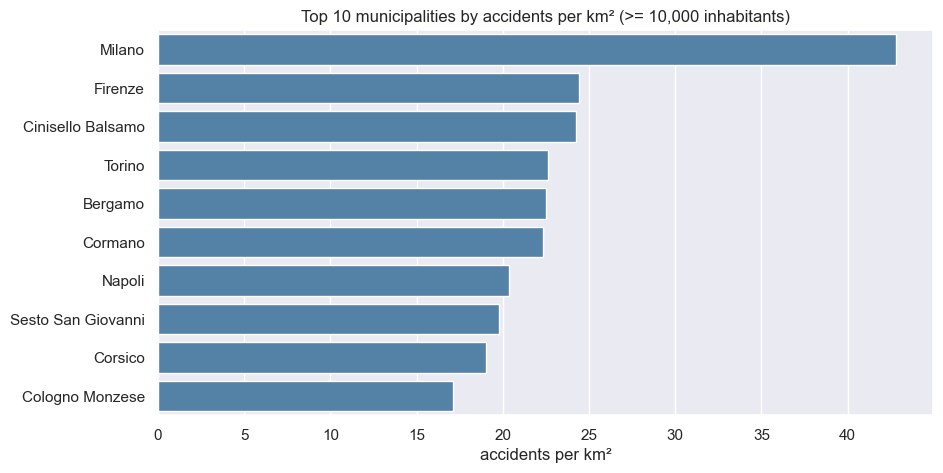

,municipality,province,density,accidents,accidents_per_km2
1775,Milano,MI,7566.02,7779.33,42.82
4228,Firenze,FI,3600.81,2499.33,24.43
1741,Cinisello Balsamo,MI,5865.72,308.67,24.26
267,Torino,TO,6598.30,2940.33,22.61
1860,Bergamo,BG,2988.51,903.67,22.51
1746,Cormano,MI,4541.74,100.00,22.35
5112,Napoli,NA,7752.33,2420.00,20.35
1815,Sesto San Giovanni,MI,6855.43,231.33,19.77
1748,Corsico,MI,6460.71,102.00,19.05
1743,Cologno Monzese,MI,5618.60,144.00,17.14


In [ ]:
top_km2 = big.sort_values("accidents_per_km2", ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_km2, x="accidents_per_km2", y="municipality", color="steelblue")
plt.title("Top 10 municipalities by accidents per km² (>= 10,000 inhabitants)")
plt.xlabel("accidents per km²")
plt.ylabel("")
plt.show()

top_km2[["municipality", "province", "density", "accidents", "accidents_per_km2"]].round(2)

# Thismetric is more influenced by population density than by the number of accidents: the top 10 is full of very dense cities (Naples, Milan, Genoa, Florence, Rome, Turin) with a lot of traffic and therefore a higher risk of accidents.

In [59]:
top_severity = big.sort_values("killed_per_100_acc", ascending=False).head(10)
top_severity[["municipality", "province", "accidents", "killed", "killed_per_100_acc"]].round(2)

,municipality,province,accidents,killed,killed_per_100_acc
5941,Mottola,TA,23.33,7.33,31.43
5867,San Nicandro Garganico,FG,12.33,3.33,27.03
6583,Corleone,PA,11.33,2.33,20.59
805,Nizza Monferrato,AT,15.00,2.33,15.56
4972,Teano,CE,13.67,2.00,14.63
6861,Ramacca,CT,12.00,1.67,13.89
6313,San Giovanni in Fiore,CS,7.33,1.00,13.64
5931,Laterza,TA,32.67,4.33,13.27
6862,Randazzo,CT,11.33,1.33,11.76
4767,Itri,LT,24.33,2.67,10.96



-  **high rate** per inhabitant (roads are more dangerous than average),

-  **high density** of accidents per km² (interventions are concentrated),

-  **high number** of accidents (the impact of the investment is large).

We combine the three with a simple **score**: for each metric we compute the *percentile rank* (0 = lowest, 1 = highest among the 1,206 municipalities) and take the average.

In [60]:
big["score"] = (big["accidents_per_1000"].rank(pct=True) +
                big["accidents_per_km2"].rank(pct=True) +
                big["accidents"].rank(pct=True)) / 3

top_score = big.sort_values("score", ascending=False).head(15)
top_score[["municipality", "province", "population", "accidents",
           "accidents_per_1000", "accidents_per_km2", "score"]].round(2)

,municipality,province,population,accidents,accidents_per_1000,accidents_per_km2,score
4228,Firenze,FI,368419,2499.33,6.78,24.43,1.00
1860,Bergamo,BG,119993,903.67,7.53,22.51,0.99
1266,Genova,GE,566410,3817.00,6.74,15.89,0.99
1775,Milano,MI,1374582,7779.33,5.66,42.82,0.99
3841,Bologna,BO,391686,2074.67,5.30,14.73,0.98
2655,Bolzano/Bozen,BZ,107467,659.33,6.14,12.61,0.98
5886,Bari,BA,317205,1615.33,5.09,13.76,0.98
4265,Livorno,LI,155370,940.00,6.05,8.98,0.98
3397,Padova,PD,209730,1047.00,4.99,11.25,0.97
4727,Roma,RM,2770226,13307.33,4.80,10.34,0.97


   ## 6. Clustering
We group the municipalities (>= 10,000 inhabitants) into **risk profiles** with K-Means, using three features:
- `accidents_per_1000` → how dangerous the roads are for the inhabitants

- `accidents_per_km2` → how concentrated the accidents are on the territory

- `killed_per_100_acc` → how severe the accidents are

We don't use population or the number of accidents: they measure the size of the city, and we want groups based on **risk**.

K-Means is based on distances, so we:
1. apply a **logarithm** to `accidents_per_km2`, which is very skewed (from ~0 to 43 in Milan): `np.log1p(x)` = log(1 + x), which also works when x = 0;

2. **normalize** all features to [0, 1] with `MinMaxScaler`, so they have the same weight.

In [61]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

big["log_accidents_per_km2"] = np.log1p(big["accidents_per_km2"])

features = ["accidents_per_1000", "log_accidents_per_km2", "killed_per_100_acc"]

scale_norm = MinMaxScaler()
scaled = pd.DataFrame(scale_norm.fit_transform(big[features]), columns=features)

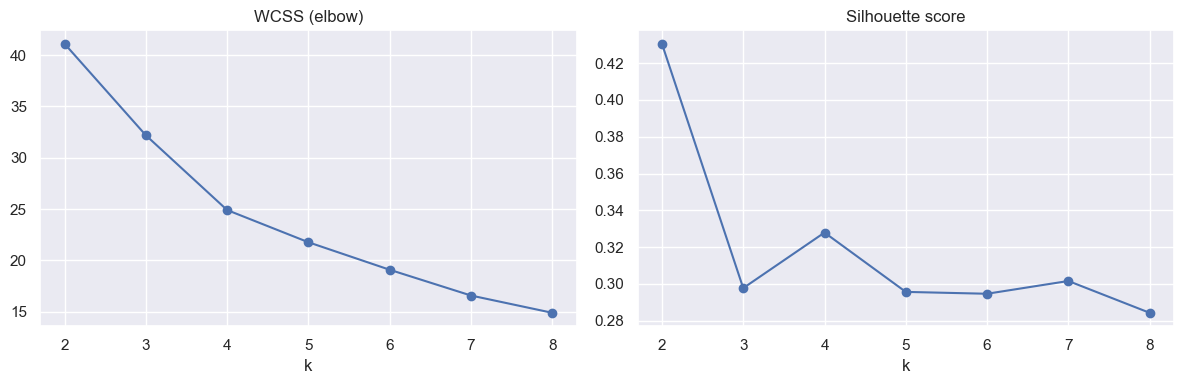

In [ ]:
# Number of clusters
#We use the **elbow method** (WCSS) and the silhouette score(higher is better) for k from 2 to 8.
    
k_values =list(range(2, 9))
wcss_list = []
silhouette_list = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled)
    wcss_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, wcss_list, marker="o")
axes[0].set_title("WCSS (elbow)")
axes[0].set_xlabel("k")

axes[1].plot(k_values, silhouette_list, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")

plt.tight_layout()
plt.show()

In [63]:
kmeans_4 = KMeans(n_clusters=4, random_state=42)
kmeans_4.fit(scaled)
big["cluster"] = kmeans_4.labels_

summary = big.groupby("cluster").agg(municipalities=("code", "count"),
                                     accidents_per_1000=("accidents_per_1000", "median"),
                                     accidents_per_km2=("accidents_per_km2", "median"),
                                     killed_per_100_acc=("killed_per_100_acc", "median"),
                                     population=("population", "median"),
                                     total_accidents=("accidents", "sum")).round(2)

summary["share_of_accidents_%"] = (summary["total_accidents"] / summary["total_accidents"].sum() * 100).round(1)
summary

,municipalities,accidents_per_1000,accidents_per_km2,killed_per_100_acc,population,total_accidents,share_of_accidents_%
cluster,,,,,,,
0,366,3.11,1.22,1.73,18971.0,37683.67,27.5
1,497,1.74,0.52,2.56,13905.0,16272.67,11.9
2,128,4.59,6.00,0.81,43633.0,70024.67,51.2
3,215,2.08,3.64,1.37,21307.0,12844.33,9.4


In [64]:
# example municipalities (the ones with most accidents) for each cluster
for c in sorted(big["cluster"].unique()):
    examples = big[big["cluster"] == c].sort_values("accidents", ascending=False)["municipality"].head(6)
    print("cluster", c, ":", list(examples))

# in which macro areas are the clusters? (share of each row)
pd.crosstab(big["cluster"], big["macro_area"], normalize="index").round(2)

cluster 0 : ['Ravenna', 'Parma', 'Taranto', 'Venezia', 'Ferrara', 'Forlì']
cluster 1 : ['Andria', 'Marsala', "L'Aquila", 'Catanzaro', 'Ragusa', 'Cerignola']
cluster 2 : ['Roma', 'Milano', 'Genova', 'Torino', 'Firenze', 'Napoli']
cluster 3 : ['Messina', 'Cagliari', 'Pozzuoli', 'Giugliano in Campania', 'Frosinone', 'Cosenza']


macro_area,Centre,Islands,North-East,North-West,South
cluster,,,,,
0,0.31,0.05,0.34,0.12,0.18
1,0.13,0.19,0.21,0.17,0.30
2,0.21,0.05,0.17,0.48,0.09
3,0.07,0.08,0.08,0.42,0.34


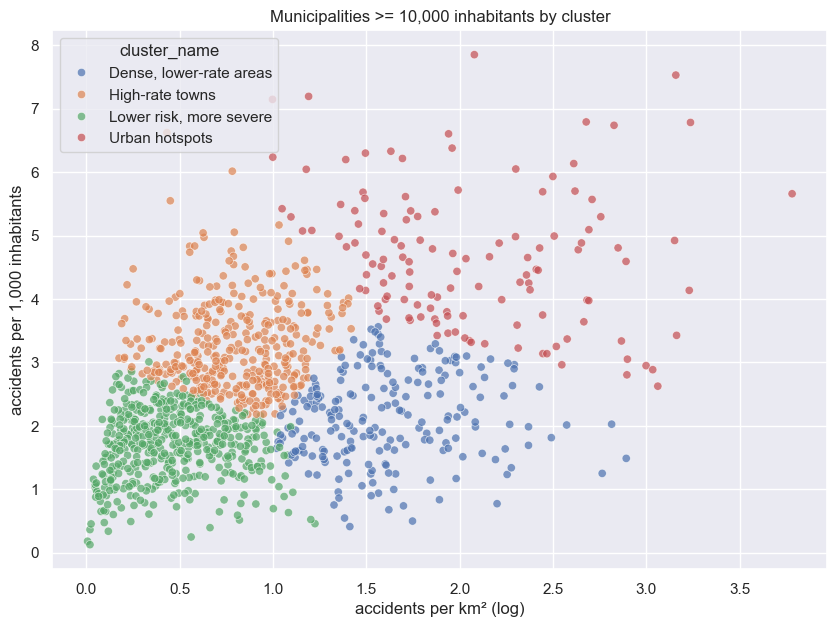

In [65]:
# match the names to the summary table (e.g. highest accidents per km² = "Urban hotspots")
cluster_names = {2: "Urban hotspots",
                 0: "High-rate towns",
                 3: "Dense, lower-rate areas",
                 1: "Lower risk, more severe"}

big["cluster_name"] = big["cluster"].replace(cluster_names)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=big, x="log_accidents_per_km2", y="accidents_per_1000",
                hue="cluster_name", alpha=0.7)
plt.title("Municipalities >= 10,000 inhabitants by cluster")
plt.xlabel("accidents per km² (log)")
plt.ylabel("accidents per 1,000 inhabitants")
plt.show()

## 7. Hypothesis test: is the accident rate different between Centre-North and South?

In the EDA we saw that, compared to their population, the **South** has fewer accidents than the rest of Italy. Is this difference **real**, or could it happen by chance?

We compare the `accidents_per_1000` of the municipalities with >= 10,000 inhabitants, split into two groups as in the ISTAT definition:
- **Centre-North** = North-West + North-East + Centre (*Centro-Nord*)
- **South** = South + Islands (*Mezzogiorno*)

**Hypotheses:**
- $H_0: \mu_{Centre-North} = \mu_{South}$ (no difference)
- $H_1: \mu_{Centre-North} > \mu_{South}$ (the Centre-North has a higher accident rate)

Significance level: $\alpha = 0.05$

In [66]:
big["zone"] = big["macro_area"].replace({"North-West": "Centre-North", "North-East": "Centre-North",
                                         "Centre": "Centre-North",
                                         "South": "South", "Islands": "South"})

big.groupby("zone")["accidents_per_1000"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
zone,,,,
Centre-North,768,2.88,2.69,1.21
South,438,2.01,1.85,0.93


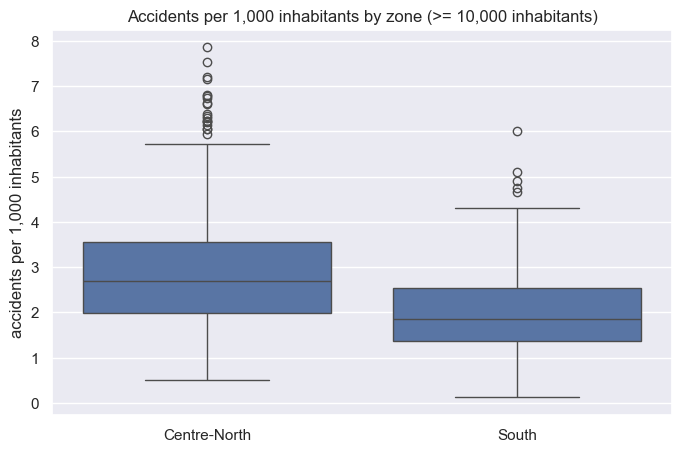

In [67]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=big, x="zone", y="accidents_per_1000", order=["Centre-North", "South"])
plt.title("Accidents per 1,000 inhabitants by zone (>= 10,000 inhabitants)")
plt.xlabel("")
plt.ylabel("accidents per 1,000 inhabitants")
plt.show()

In [68]:
north = big[big["zone"] == "Centre-North"]["accidents_per_1000"]
south = big[big["zone"] == "South"]["accidents_per_1000"]

mu_diff = np.mean(north) - np.mean(south)
print("observed difference (Centre-North - South):", round(mu_diff, 2))

observed difference (Centre-North - South): 0.87


###  Permutation test
If $H_0$ is true, the label "Centre-North" or "South" doesn't matter. So we **shuffle** the labels many times, recompute the difference each time, and check how often we get a difference at least as big as the observed one.
*(The two groups have different sizes, so the first sample has the same size as the Centre-North group.)*

In [69]:
ns = big[["zone", "accidents_per_1000"]].reset_index(drop=True)

n = 2000
np.random.seed(42)
mu_diff_samples = []

for i in range(n):
    # random sample with the same size as the Centre-North group, without replacement
    df_sample1 = ns.sample(n=len(north), replace=False)
    # the rows not extracted form the second group
    ix2 = set(ns.index) - set(df_sample1.index)
    df_sample2 = ns.iloc[list(ix2)]
    # difference in the means
    mu_diff_temp = np.mean(df_sample1["accidents_per_1000"]) - np.mean(df_sample2["accidents_per_1000"])
    mu_diff_samples.append(mu_diff_temp)

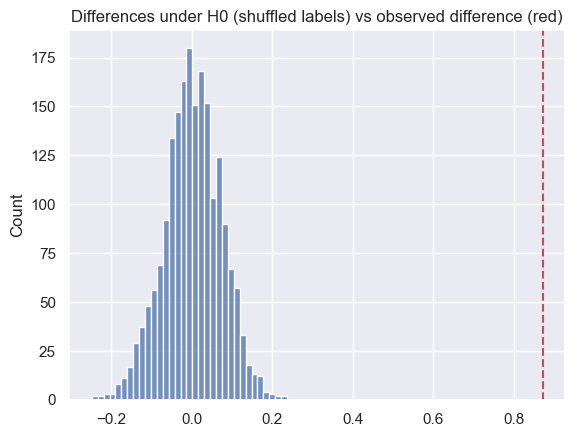

largest shuffled difference: 0.24
p-value: 0.0


In [70]:
sns.histplot(mu_diff_samples)
plt.axvline(mu_diff, 0, 1, color="r", linestyle="--")
plt.title("Differences under H0 (shuffled labels) vs observed difference (red)")
plt.show()

print("largest shuffled difference:", round(max(mu_diff_samples), 2))
p_value = sum([el >= mu_diff for el in mu_diff_samples]) / n
print("p-value:", p_value)

### t-test
For completeness we run a t-test as well (one-sided, same hypotheses):

In [71]:
t_test = stats.ttest_ind(north, south, alternative="greater")
print(t_test)

alpha = 0.05
if t_test.pvalue <= alpha:
    print("p-value <= alpha | the difference is statistically significant | H0 rejected")
else:
    print("p-value > alpha | the difference is not statistically significant | H0 accepted")

TtestResult(statistic=13.011941391782191, pvalue=1.2967773739764381e-36, df=1204.0)
p-value <= alpha | the difference is statistically significant | H0 rejected


**Conclusion:** both tests reject $H_0$ (p-value practically 0). Municipalities in the **Centre-North have a significantly higher accident rate** than those in the South: on average **2.88 vs 2.01 accidents per 1,000 inhabitants** (+43%).

**Possible explanations** (the test tells us *that* there is a difference, not *why*):
- more traffic and commuting in the Centre-North (more cars on the road per inhabitant);
- tourism: in tourist areas the people on the roads are many more than the residents (see section 5);
- differences in how accidents are **reported**: the ISTAT data only include accidents with injuries recorded by the police, and reporting habits may differ across the country.

**Business reading:** the Centre-North is where accidents are **more frequent**, while the South has fewer but, as we saw in the clustering, **more severe** accidents. The two areas need different kinds of interventions.

## 8. Regression

### 8.1 What explains the accident rate?
We use a **multiple linear regression** (OLS) to explain `accidents_per_1000` (municipalities >= 10,000 inhabitants) with:
- `log_population` → size of the city (log, because population is very skewed)
- `log_density` → how dense the city is (log, same reason)
- `centre_north` → 1 if the municipality is in the Centre-North, 0 if in the South

This also checks if the Centre-North / South difference found in section 7 is still there **when we compare cities of the same size and density**.

In [72]:
import statsmodels.api as sm

big["log_population"] = np.log10(big["population"])
big["log_density"] = np.log10(big["density"])
big["centre_north"] = (big["zone"] == "Centre-North").astype(int)

X = sm.add_constant(big[["log_population", "log_density", "centre_north"]])
y = big["accidents_per_1000"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     accidents_per_1000   R-squared:                       0.311
Model:                            OLS   Adj. R-squared:                  0.310
Method:                 Least Squares   F-statistic:                     181.2
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           6.46e-97
Time:                        23:03:16   Log-Likelihood:                -1699.8
No. Observations:                1206   AIC:                             3408.
Df Residuals:                    1202   BIC:                             3428.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -4.9155      0.407    -12.

### 8.2 Forecasting the national trend
The business asked for an option for **forecasting**. With only 10 yearly values we use a simple **linear trend** (OLS with the year as the only variable).
We **exclude 2020 and 2021**: they are COVID years and would pull the trend down artificially.

In [73]:
train = national[~national.index.isin([2020, 2021])]

X_year = sm.add_constant(train.index.values)

model_acc = sm.OLS(train["accidents"], X_year).fit()
model_killed = sm.OLS(train["killed"], X_year).fit()
model_injured = sm.OLS(train["injured"], X_year).fit()

print("accidents: slope =", round(model_acc.params.iloc[1]), "per year | p-value =", round(model_acc.pvalues.iloc[1], 3), "| R² =", round(model_acc.rsquared, 2))
print("killed:    slope =", round(model_killed.params.iloc[1]), "per year | p-value =", round(model_killed.pvalues.iloc[1], 4), "| R² =", round(model_killed.rsquared, 2))
print("injured:   slope =", round(model_injured.params.iloc[1]), "per year | p-value =", round(model_injured.pvalues.iloc[1], 4), "| R² =", round(model_injured.rsquared, 2))

accidents: slope = -771 per year | p-value = 0.058 | R² = 0.48
killed:    slope = -42 per year | p-value = 0.0007 | R² = 0.87
injured:   slope = -2650 per year | p-value = 0.0039 | R² = 0.78


In [74]:
future_years = [2025, 2026, 2027]
X_future = sm.add_constant(pd.Series(future_years), has_constant="add")

forecast = pd.DataFrame({"year": future_years,
                         "accidents_forecast": model_acc.predict(X_future).round(0),
                         "injured_forecast": model_injured.predict(X_future).round(0),
                         "killed_forecast": model_killed.predict(X_future).round(0)})
forecast

,year,accidents_forecast,injured_forecast,killed_forecast
0,2025,167538.0,223401.0,2988.0
1,2026,166767.0,220751.0,2946.0
2,2027,165996.0,218101.0,2904.0


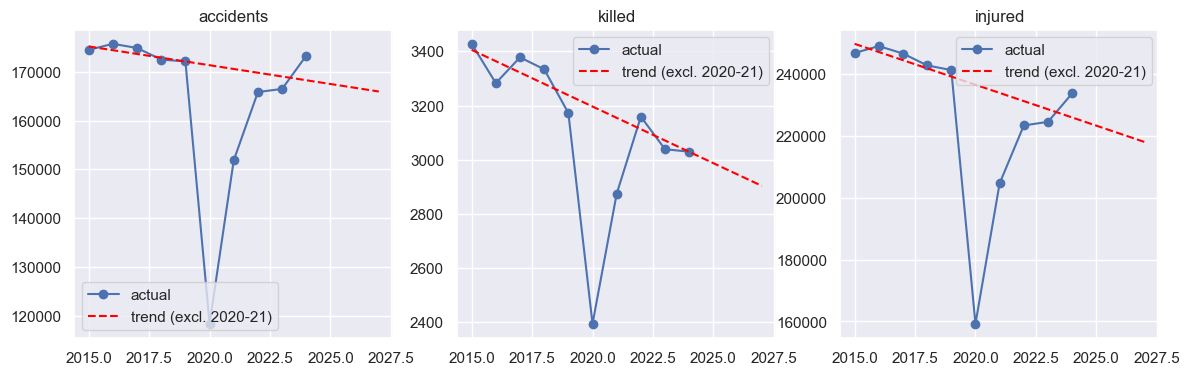

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col, mod in [(axes[0], "accidents", model_acc), (axes[1], "killed", model_killed), (axes[2], "injured", model_injured)]:
    # actual values
    ax.plot(national.index, national[col], marker="o", label="actual")
    # trend line + forecast
    all_years = list(national.index) + future_years
    trend = mod.predict(sm.add_constant(pd.Series(all_years), has_constant="add"))
    ax.plot(all_years, trend, linestyle="--", color="red", label="trend (excl. 2020-21)")
    ax.set_title(col)
    ax.legend()

plt.show()

### 9. Export for Power BI

In [76]:
# We save three files in `data/processed/` (the function is in `utilities.py`):
# 1. **municipalities.csv** → one row per municipality: average 2022-2024 values, rates, score and cluster (score and cluster only for municipalities >= 10,000 inhabitants)
# 2. **accidents_by_year.csv** → one row per municipality and year (2015-2024)
# 3. **national_trend.csv** → national totals per year + forecast 2025-2027

utilities.export_powerbi(mun, big, df, national, forecast)

municipalities.csv: (7896, 20)
accidents_by_year.csv: (78478, 14)
national_trend.csv: (13, 5)
